# 03 · Interpretación del modelo y entrega para el dashboard

**Objetivo.** Responder dos preguntas que haría un gerente:

1. **¿Por qué el modelo dice que un cliente se va?** Qué variables pesan más y en qué dirección.
2. **¿A quién llamo primero?** Un CSV con la probabilidad de abandono y el segmento de riesgo de cada cliente, listo para Tableau.

Herramientas:
- **Importancia por permutación** sobre el modelo final (boosting): se baraja una variable y se mide cuánto empeora el modelo. Mide uso real de la variable sobre datos no vistos.
- **Coeficientes de la regresión logística** como segunda opinión: dan dirección y magnitud en una escala comparable.
- **Gráficos de dependencia parcial**: cómo cambia la probabilidad predicha al mover una variable, dejando las demás fijas.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import PartialDependenceDisplay

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src.datos import COLUMNA_ID, COLUMNA_OBJETIVO, dividir_train_test, separar_predictores_objetivo
from src.interpretacion import (DICCIONARIO_VARIABLES, coeficientes_logistica, graficar_importancias,
                                importancia_permutacion, segmentar_riesgo, traducir)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

OUTPUTS = RAIZ / "outputs"
FIGURAS = OUTPUTS / "figuras"

In [2]:
df = pd.read_csv(RAIZ / "data" / "processed" / "clientes_limpios.csv")
train, test = dividir_train_test(df, proporcion_test=0.2, semilla=42)  # misma semilla => misma partición que el notebook 02
X_train, y_train = separar_predictores_objetivo(train)
X_test, y_test = separar_predictores_objetivo(test)

modelo = joblib.load(OUTPUTS / "modelo_final.joblib")
logistica = joblib.load(OUTPUTS / "modelo_logistica.joblib")
with open(OUTPUTS / "metricas.json", encoding="utf-8") as f:
    metricas = json.load(f)
UMBRAL = metricas["umbral"]
print(f"Modelo final: {metricas['modelo_final']}  |  umbral operativo: {UMBRAL:.3f}")

Modelo final: HistGradientBoosting  |  umbral operativo: 0.674


## 1. ¿Qué variables usa el modelo? Importancia por permutación

Se calcula sobre el **test** (datos que el modelo nunca vio) midiendo la caída en PR-AUC. Se permuta cada columna original completa, de modo que una variable categórica se evalúa como bloque y no dummy por dummy. Se repite 20 veces para obtener una barra de error.

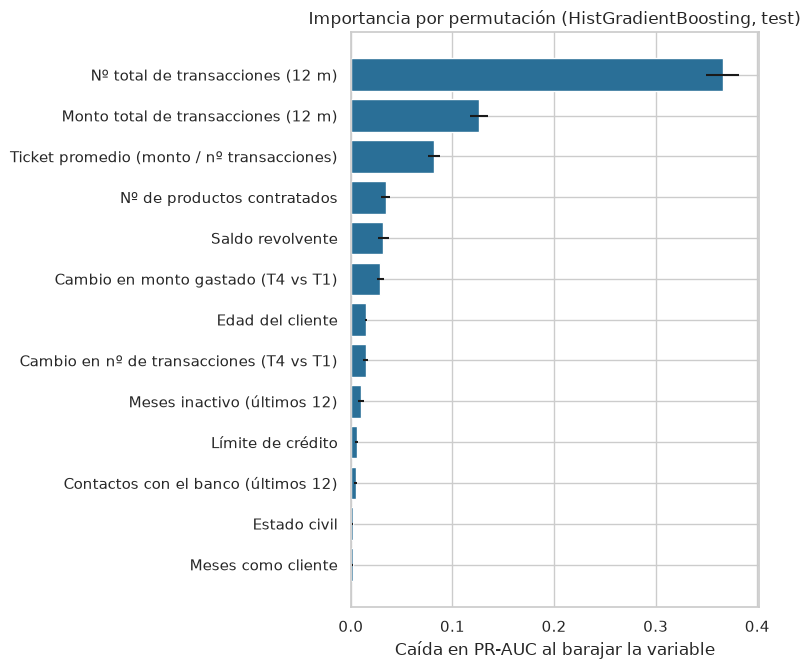

,variable,variable_negocio,importancia_media,importancia_std
0,Total_Trans_Ct,Nº total de transacciones (12 m),0.3660,0.0164
1,Total_Trans_Amt,Monto total de transacciones (12 m),0.1260,0.0091
2,Ticket_Promedio,Ticket promedio (monto / nº transacciones),0.0816,0.0058
3,Total_Relationship_Count,Nº de productos contratados,0.0345,0.0043
4,Total_Revolving_Bal,Saldo revolvente,0.0319,0.0053
5,Total_Amt_Chng_Q4_Q1,Cambio en monto gastado (T4 vs T1),0.0288,0.0034
6,Customer_Age,Edad del cliente,0.0149,0.0012
7,Total_Ct_Chng_Q4_Q1,Cambio en nº de transacciones (T4 vs T1),0.0145,0.0024
8,Months_Inactive_12_mon,Meses inactivo (últimos 12),0.0101,0.0030
9,Credit_Limit,Límite de crédito,0.0056,0.0018


In [3]:
importancias = importancia_permutacion(modelo, X_test, y_test, metrica="average_precision", n_repeticiones=20)
graficar_importancias(importancias, top=13, titulo="Importancia por permutación (HistGradientBoosting, test)",
                      ruta_guardado=FIGURAS / "03_importancia_permutacion.png")
plt.show()
importancias.round(4)

**Lectura.** El modelo se apoya casi por completo en el **comportamiento transaccional**:

1. **Nº de transacciones** (caída de 0.37 en PR-AUC si se baraja), **monto de transacciones** (0.13) y **ticket promedio** (0.08) explican por sí solas la mayor parte del poder predictivo. Las tres describen lo mismo desde ángulos distintos: cuánto, cuántas veces y de qué tamaño usa la tarjeta el cliente.
2. Un segundo grupo con importancia moderada: **nº de productos**, **saldo revolvente**, **cambio en monto T4/T1**, **cambio en nº de transacciones T4/T1**, **meses inactivo**, **edad**.
3. **Las variables demográficas** (género, educación, estado civil, ingresos, tipo de tarjeta, dependientes) tienen importancia ≈ 0. El modelo las ignora, exactamente como anticipó el EDA.

Un punto interesante: `Contacts_Count_12_mon` fue una señal muy clara en el EDA (6 contactos → 100% abandono), pero aquí aparece con importancia baja. No significa que no importe, sino que **su información ya está contenida en las variables transaccionales**: el cliente que llama muchas veces es el mismo que dejó de usar la tarjeta. Al permutar contactos, el modelo sigue acertando por las otras variables.

## 2. Dirección del efecto: coeficientes de la regresión logística

El boosting dice *qué* variables usa pero no *en qué dirección*. La regresión logística (entrenada en el notebook 02) sí lo dice. Como las numéricas están estandarizadas, los coeficientes son comparables entre sí.

**Cómo leer el odds ratio:** si vale 1.75, aumentar la variable en una desviación estándar multiplica por 1.75 las "chances" de abandono. Si vale 0.55, las divide casi a la mitad.

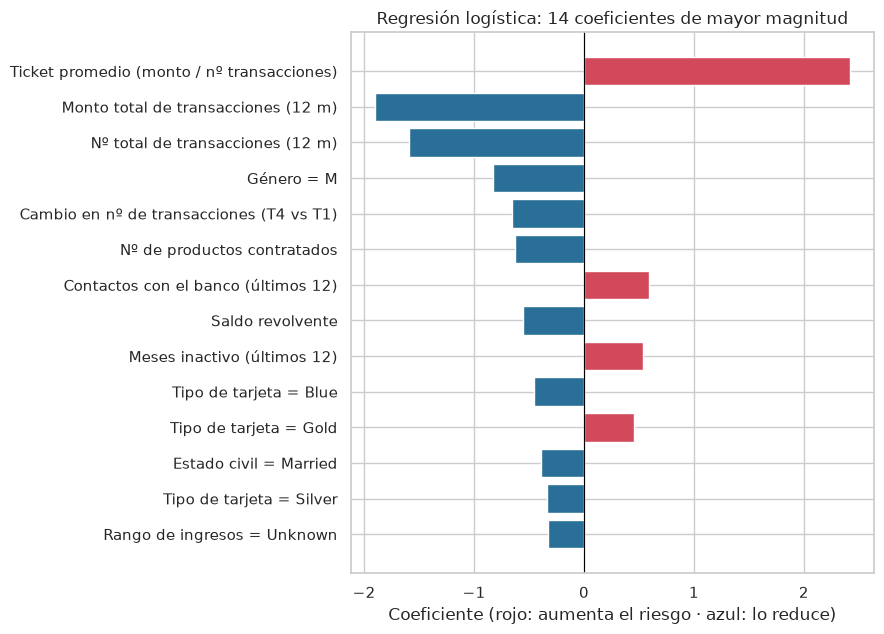

,variable,variable_negocio,coeficiente,odds_ratio
0,Ticket_Promedio,Ticket promedio (monto / nº transacciones),2.421,11.261
1,Total_Trans_Amt,Monto total de transacciones (12 m),-1.904,0.149
2,Total_Trans_Ct,Nº total de transacciones (12 m),-1.590,0.204
3,Gender_M,Género = M,-0.824,0.439
4,Total_Ct_Chng_Q4_Q1,Cambio en nº de transacciones (T4 vs T1),-0.655,0.519
5,Total_Relationship_Count,Nº de productos contratados,-0.628,0.534
6,Contacts_Count_12_mon,Contactos con el banco (últimos 12),0.592,1.808
7,Total_Revolving_Bal,Saldo revolvente,-0.554,0.575
8,Months_Inactive_12_mon,Meses inactivo (últimos 12),0.540,1.716
9,Card_Category_Blue,Tipo de tarjeta = Blue,-0.456,0.634


In [4]:
coefs = coeficientes_logistica(logistica)
top = coefs.head(14).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6.5))
colores = ["#d1495b" if c > 0 else "#2a6f97" for c in top["coeficiente"]]
ax.barh(top["variable_negocio"], top["coeficiente"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Coeficiente (rojo: aumenta el riesgo · azul: lo reduce)",
       title="Regresión logística: 14 coeficientes de mayor magnitud")
fig.tight_layout()
fig.savefig(FIGURAS / "03_coeficientes_logistica.png", bbox_inches="tight")
plt.show()
coefs.head(14).round(3)

**Lectura (y una advertencia).**

- **Reducen el riesgo** (azul): más monto gastado, más transacciones, mayor saldo revolvente, más productos, crecimiento de actividad T4 vs T1, ser hombre, estar casado.
- **Aumentan el riesgo** (rojo): **ticket promedio** (el coeficiente más grande, odds ratio ≈ 11), más contactos con el banco, más meses inactivo, tarjeta Gold.
- **Lectura del ticket promedio**: *a igual monto y número de transacciones*, el cliente que concentra su gasto en pocas compras grandes tiene mucho más riesgo que el que hace muchas compras pequeñas. El uso frecuente es lo que retiene, no el monto.

**Nota metodológica.** Sin la variable `Ticket_Promedio`, el monto de transacciones aparecía con signo positivo (más gasto → más riesgo), contrario al EDA. Era un artefacto de la colinealidad entre monto y nº de transacciones (correlación 0.81): el modelo lineal usaba el monto como sustituto del ticket. Crear la variable derivada explícita devolvió a cada coeficiente su signo natural y subió el PR-AUC de la logística de 0.75 a 0.77. Es un ejemplo de por qué el EDA y la interpretación deben retroalimentar la ingeniería de variables.

## 3. ¿Cómo cambia el riesgo al mover cada variable? Dependencia parcial

Para las 6 variables más importantes del boosting, el gráfico muestra la probabilidad media de abandono que predice el modelo a medida que cambia esa variable, manteniendo todas las demás como están. Las marcas en el eje X indican dónde hay clientes reales.

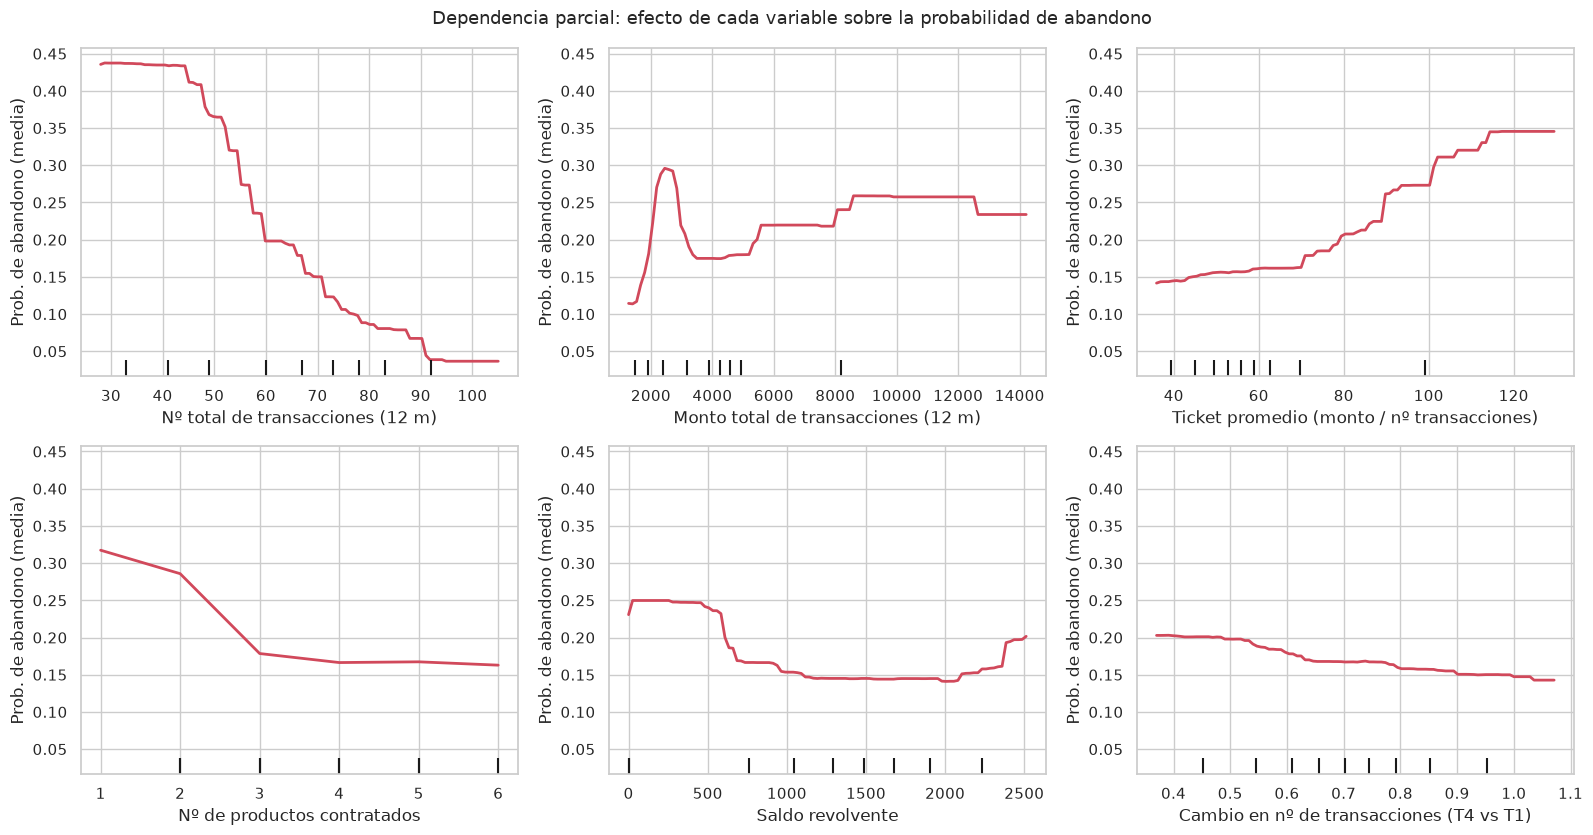

In [5]:
variables_pd = ["Total_Trans_Ct", "Total_Trans_Amt", "Ticket_Promedio",
                "Total_Relationship_Count", "Total_Revolving_Bal", "Total_Ct_Chng_Q4_Q1"]

# sklearn exige columnas numéricas en float para la dependencia parcial
X_pd = X_train.copy()
for col in X_pd.select_dtypes("number").columns:
    X_pd[col] = X_pd[col].astype(float)

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
PartialDependenceDisplay.from_estimator(
    modelo, X_pd, features=variables_pd, kind="average", ax=axes.ravel(),
    response_method="predict_proba", n_jobs=-1, random_state=42,
    line_kw={"color": "#d1495b", "lw": 2},
)
for ax, var in zip(axes.ravel(), variables_pd):
    ax.set(xlabel=traducir(var), ylabel="Prob. de abandono (media)")
    ax.axhline(UMBRAL, color="gray", ls="--", lw=1)
fig.suptitle("Dependencia parcial: efecto de cada variable sobre la probabilidad de abandono", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURAS / "03_dependencia_parcial.png", bbox_inches="tight")
plt.show()

**Lectura.**

- **Nº de transacciones**: la variable con mayor pendiente. El riesgo medio pasa de ~0.44 con 30 transacciones al año a ~0.10 con 70 y a ~0.04 por encima de 90. Un cliente que usa la tarjeta más de ~1.5 veces por semana prácticamente no abandona.
- **Ticket promedio**: efecto creciente y casi monótono, de ~0.15 con tickets de $40 a ~0.35 con tickets de $120 o más. *A igual número de transacciones*, pocas compras grandes = riesgo; muchas compras pequeñas = fidelidad.
- **Monto de transacciones**: una vez que el ticket promedio está en el modelo, el monto queda con un efecto moderado e irregular (un pico cerca de $2,500 y una ligera subida por encima de $6,000). Antes de crear el ticket, esta curva subía con fuerza porque el monto hacía de sustituto del ticket.
- **Nº de productos**: 1-2 productos → ~0.30; a partir de 3 el riesgo baja a ~0.17 y se estabiliza.
- **Saldo revolvente**: ~0.25 con saldo cero, cae a ~0.15 a partir de ~$700. Tener algo de saldo financiado "ancla" al cliente.
- **Cambio T4/T1**: efecto suave (0.20 → 0.14), menor de lo que sugería el EDA. Su información ya está en gran parte capturada por el nº de transacciones: el modelo la usa como ajuste fino, no como señal principal.

Estos escalones son la razón de que los árboles ganen a la regresión logística: la realidad tiene umbrales, no pendientes constantes.

## 4. Traducción para la gerencia

**Qué dice el modelo, en una frase:** *un cliente está en riesgo de abandono cuando deja de usar la tarjeta, no por quién es.*

| Señal | Qué observar | Umbral de alerta orientativo | Acción sugerida |
|---|---|---|---|
| Frecuencia de uso | Transacciones en los últimos 12 meses | Menos de ~55 al año (menos de 1 por semana) | Promociones de uso recurrente (cashback en compras frecuentes, suscripciones) |
| Patrón de gasto | Ticket promedio (monto / nº de transacciones) | Pocas compras grandes en vez de muchas pequeñas | Incentivar el uso cotidiano (supermercado, transporte, suscripciones), no solo compras grandes |
| Tendencia de uso | Transacciones del último trimestre vs. el primero | Ratio por debajo de 0.6 | Alerta temprana: contactar antes de que el uso llegue a cero |
| Vínculo con el banco | Nº de productos contratados | 1 o 2 productos | Venta cruzada (cuenta de ahorros, préstamo, seguro) |
| Saldo | Saldo revolvente | Cero durante varios meses | Oferta de compras en cuotas sin interés para crear vínculo |
| Inactividad | Meses sin usar la tarjeta | 3 o más | Campaña de reactivación |
| Insatisfacción | Contactos con el banco en el año | 4 o más | Escalar a retención y revisar motivo de las llamadas |

**Lo que NO funciona:** campañas segmentadas por edad, género, educación, estado civil o nivel de ingresos. El modelo no usa esas variables y el EDA mostró tasas de abandono casi idénticas en todos los grupos.

## 5. Perfil del cliente en riesgo frente al cliente fiel

Comparamos los clientes del test que el modelo marca como riesgo alto frente al resto.

In [6]:
proba_test = pd.read_csv(OUTPUTS / "probas_test.csv").set_index(COLUMNA_ID).loc[test[COLUMNA_ID], "probabilidad_abandono"].values
test_eval = test.copy()
test_eval["probabilidad_abandono"] = proba_test
test_eval["marcado_riesgo"] = np.where(proba_test >= UMBRAL, "Riesgo alto", "Resto")

variables_perfil = ["Total_Trans_Ct", "Total_Trans_Amt", "Ticket_Promedio", "Total_Ct_Chng_Q4_Q1", "Total_Relationship_Count",
                    "Total_Revolving_Bal", "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Customer_Age"]
perfil = test_eval.groupby("marcado_riesgo")[variables_perfil].median().T
perfil.index = [traducir(v) for v in perfil.index]

tasas = test_eval.groupby("marcado_riesgo")[COLUMNA_OBJETIVO].agg(clientes="count", tasa_real_abandono="mean")
print("Clientes y tasa real de abandono por grupo:")
print(tasas.round(3).to_string(), "\n")
print("Mediana de cada variable por grupo:")
perfil.round(2)

Clientes y tasa real de abandono por grupo:
                clientes  tasa_real_abandono
marcado_riesgo                              
Resto               1716               0.021
Riesgo alto          310               0.932 

Mediana de cada variable por grupo:


marcado_riesgo,Resto,Riesgo alto
Nº total de transacciones (12 m),70.50,43.00
Monto total de transacciones (12 m),4109.00,2363.00
Ticket promedio (monto / nº transacciones),55.89,55.66
Cambio en nº de transacciones (T4 vs T1),0.72,0.54
Nº de productos contratados,4.00,3.00
Saldo revolvente,1329.50,0.00
Meses inactivo (últimos 12),2.00,3.00
Contactos con el banco (últimos 12),2.00,3.00
Edad del cliente,46.00,46.00


**Lectura.** El cliente típico marcado como riesgo alto hace la mitad de transacciones (≈ 40 frente a ≈ 70), gasta casi la mitad, redujo su actividad un 50% entre el primer y el último trimestre, tiene menos productos, saldo revolvente cero y un contacto más con el banco. Es un perfil fácil de reconocer en la operación diaria.

El ticket promedio tiene la misma mediana en ambos grupos (≈ 56). No contradice su importancia: su efecto es **condicional** (a igual nº de transacciones, ticket alto = riesgo), y eso no se ve en una mediana marginal. Es una buena advertencia sobre leer importancias y medianas por separado.

## 6. CSV para el dashboard en Tableau

Un archivo con **todos los clientes** (10,127), su probabilidad de abandono y su segmento de riesgo.

**Decisión importante:** para los clientes del train no usamos la predicción del modelo final (que los vio al entrenar y los "recuerda"), sino la **probabilidad fuera de muestra** obtenida por validación cruzada en el notebook 02. Así, cada cliente del CSV tiene una probabilidad honesta, comparable con la de los clientes del test.

**Segmentos:**
- **Alto**: probabilidad ≥ umbral operativo (0.67). Contactar.
- **Medio**: entre 0.30 y el umbral. Vigilar; candidatos si sobra presupuesto.
- **Bajo**: resto.

Las columnas se renombran al español para que el dashboard no necesite traducción.

In [7]:
CORTE_MEDIO = 0.30

probas_train = pd.read_csv(OUTPUTS / "probas_cv_train.csv")
probas_test_df = pd.read_csv(OUTPUTS / "probas_test.csv")
probas_train["conjunto"] = "train (prob. validación cruzada)"
probas_test_df["conjunto"] = "test (prob. modelo final)"
probas = pd.concat([probas_train, probas_test_df], ignore_index=True)

salida = df.merge(probas, on=COLUMNA_ID, how="left")
assert salida["probabilidad_abandono"].notna().all(), "Hay clientes sin probabilidad"

salida["segmento_riesgo"] = segmentar_riesgo(salida["probabilidad_abandono"].values, corte_alto=UMBRAL, corte_medio=CORTE_MEDIO).values
salida["abandono_real"] = salida[COLUMNA_OBJETIVO].map({0: "Se queda", 1: "Abandonó"})
salida["probabilidad_abandono"] = salida["probabilidad_abandono"].round(4)

# Renombrado a español para Tableau
renombres = {COLUMNA_ID: "id_cliente", **{k: v for k, v in DICCIONARIO_VARIABLES.items()}}
salida = salida.drop(columns=[COLUMNA_OBJETIVO]).rename(columns=renombres)

# Orden de columnas: identificación y predicción primero, luego atributos
primeras = ["id_cliente", "probabilidad_abandono", "segmento_riesgo", "abandono_real", "conjunto"]
salida = salida[primeras + [c for c in salida.columns if c not in primeras]]
salida = salida.sort_values("probabilidad_abandono", ascending=False).reset_index(drop=True)

RUTA_CSV = OUTPUTS / "predicciones_churn.csv"
salida.to_csv(RUTA_CSV, index=False, encoding="utf-8-sig")  # BOM para que Excel/Tableau lean bien las tildes
print(f"Guardado: {RUTA_CSV.relative_to(RAIZ)}  ({len(salida):,} clientes, {salida.shape[1]} columnas)")
salida.head(10)

Guardado: outputs/predicciones_churn.csv  (10,127 clientes, 24 columnas)


,id_cliente,probabilidad_abandono,segmento_riesgo,abandono_real,conjunto,Edad del cliente,Género,Nº de dependientes,Nivel educativo,Estado civil,Rango de ingresos,Tipo de tarjeta,Meses como cliente,Nº de productos contratados,Meses inactivo (últimos 12),Contactos con el banco (últimos 12),Límite de crédito,Saldo revolvente,Cambio en monto gastado (T4 vs T1),Monto total de transacciones (12 m),Nº total de transacciones (12 m),Cambio en nº de transacciones (T4 vs T1),Utilización promedio del crédito,Ticket promedio (monto / nº transacciones)
0,713283933,0.9998,Alto,Abandonó,train (prob. validación cruzada),42,M,2,Uneducated,Married,$40K - $60K,Blue,30,1,3,3,3032.0,0,0.429,2273,44,0.517,0.000,51.66
1,715016508,0.9998,Alto,Abandonó,train (prob. validación cruzada),42,F,3,High School,Married,$40K - $60K,Blue,36,1,3,4,4527.0,0,0.801,2441,37,0.370,0.000,65.97
2,805313808,0.9998,Alto,Abandonó,train (prob. validación cruzada),52,F,3,High School,Married,$40K - $60K,Blue,47,2,2,3,8018.0,134,0.717,2409,38,0.310,0.017,63.39
3,714374133,0.9998,Alto,Abandonó,train (prob. validación cruzada),56,M,2,Graduate,Married,$120K +,Blue,36,1,3,3,15769.0,0,1.041,602,15,0.364,0.000,40.13
4,712982808,0.9997,Alto,Abandonó,train (prob. validación cruzada),47,M,2,Doctorate,Divorced,$80K - $120K,Blue,32,1,3,3,1438.3,0,0.454,2388,42,0.500,0.000,56.86
5,767294658,0.9997,Alto,Abandonó,train (prob. validación cruzada),56,M,2,College,Single,$120K +,Blue,50,2,2,3,16867.0,0,0.885,654,14,0.400,0.000,46.71
6,808903308,0.9997,Alto,Abandonó,train (prob. validación cruzada),54,F,1,Unknown,Married,$40K - $60K,Blue,49,4,3,6,2471.0,0,0.722,2519,35,0.522,0.000,71.97
7,718352358,0.9997,Alto,Abandonó,train (prob. validación cruzada),49,F,3,Post-Graduate,Married,Less than $40K,Blue,35,3,3,2,1914.0,0,0.677,2687,41,0.414,0.000,65.54
8,778819083,0.9997,Alto,Abandonó,train (prob. validación cruzada),41,F,2,Doctorate,Married,$40K - $60K,Blue,33,1,3,3,1604.0,0,0.644,2264,47,0.516,0.000,48.17
9,715645908,0.9997,Alto,Abandonó,train (prob. validación cruzada),59,M,0,High School,Single,$80K - $120K,Gold,48,5,2,6,34516.0,0,0.969,8480,71,0.821,0.000,119.44


In [8]:
resumen_segmentos = (
    salida.groupby("segmento_riesgo")
    .agg(clientes=("id_cliente", "count"),
         tasa_real_abandono=("abandono_real", lambda s: (s == "Abandonó").mean()),
         prob_promedio=("probabilidad_abandono", "mean"))
    .reindex(["Alto", "Medio", "Bajo"])
)
resumen_segmentos["pct_cartera"] = resumen_segmentos["clientes"] / len(salida)
resumen_segmentos["abandonos_capturados"] = salida[salida["abandono_real"] == "Abandonó"].groupby("segmento_riesgo").size().reindex(["Alto", "Medio", "Bajo"])
resumen_segmentos["pct_abandonos_capturados"] = resumen_segmentos["abandonos_capturados"] / (salida["abandono_real"] == "Abandonó").sum()
resumen_segmentos.round(3)

,clientes,tasa_real_abandono,prob_promedio,pct_cartera,abandonos_capturados,pct_abandonos_capturados
segmento_riesgo,,,,,,
Alto,1583,0.923,0.959,0.156,1461,0.898
Medio,242,0.331,0.490,0.024,80,0.049
Bajo,8302,0.010,0.013,0.820,86,0.053


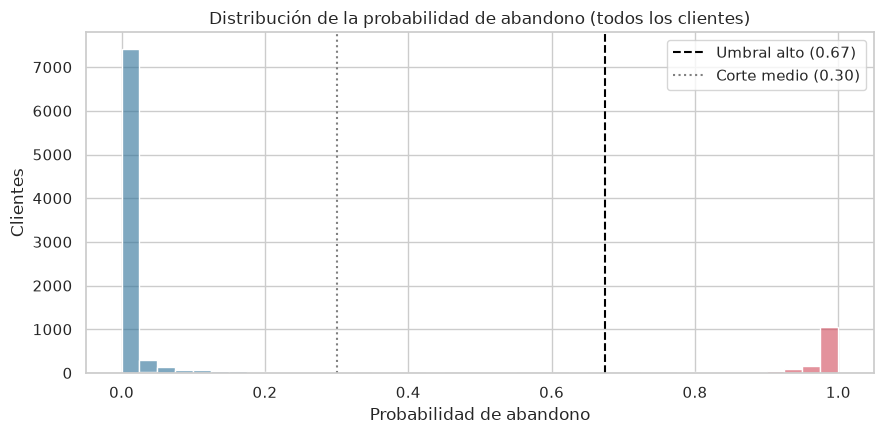

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=salida, x="probabilidad_abandono", hue="abandono_real", bins=40, stat="count",
             palette={"Se queda": "#2a6f97", "Abandonó": "#d1495b"}, alpha=0.6, ax=ax)
ax.axvline(UMBRAL, color="black", ls="--", label=f"Umbral alto ({UMBRAL:.2f})")
ax.axvline(CORTE_MEDIO, color="gray", ls=":", label=f"Corte medio ({CORTE_MEDIO:.2f})")
ax.set(title="Distribución de la probabilidad de abandono (todos los clientes)", xlabel="Probabilidad de abandono", ylabel="Clientes")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "03_distribucion_probabilidades.png", bbox_inches="tight")
plt.show()

**Lectura.** El modelo separa bien: los clientes que abandonaron se concentran cerca de 1 y los que se quedan cerca de 0. El segmento **Alto** reúne al ~15% de la cartera y contiene ~90% de los abandonos reales, con una tasa de abandono real superior al 90%. El segmento **Medio** es pequeño (~2%) y mezclado (≈ 33% de abandono): es la zona gris donde conviene decidir por presupuesto. El segmento **Bajo** (~82% de la cartera) tiene una tasa de abandono ≈ 1%: no hace falta gastar en él.

**Sugerencias para el dashboard en Tableau:**
- KPI: clientes en riesgo alto, abandonos esperados (suma de probabilidades), % de cartera a contactar.
- Lista priorizada: tabla ordenada por `probabilidad_abandono` con filtros por segmento, tipo de tarjeta y rango de ingresos.
- Gráfico de dispersión: `Nº total de transacciones` vs `Monto total de transacciones`, color por segmento.
- Histograma de probabilidad con las dos líneas de corte, para que el usuario mueva el umbral y vea cuántos clientes entran.

## 7. Conclusiones

1. El abandono se predice por **comportamiento**, no por demografía. Las tres variables de uso de la tarjeta (número, monto y ticket promedio de las transacciones) concentran la mayor parte del poder predictivo; las demográficas no aportan nada.
2. La **caída de actividad entre trimestres** es la señal de alerta temprana más accionable: permite intervenir antes de que el cliente llegue a la inactividad total.
3. El modelo final (boosting) detecta el **89% de los abandonos** contactando al **15% de la cartera**, con un 93% de acierto entre los contactados.
4. El CSV `outputs/predicciones_churn.csv` entrega una probabilidad honesta (fuera de muestra) para cada uno de los 10,127 clientes, con segmento de riesgo y variables en español, listo para Tableau.

**Limitaciones** (detalladas en el README): no hay fechas ni costos reales, el dataset es una foto estática, y la definición de "abandono" (cuenta cerrada) llega tarde respecto a la señal de uso.